# Native Gridded Import and Grid Tools on Real Precipitation

This notebook drives `RasDssGrid`, RAS Commander's wrapper of the gridded importer
and grid tools in the optional `ras-commander-fast-dss` engine. It imports real
precipitation from local Zarr, NetCDF, HDF5 and GRIB2 sources into DSS grids, and
processes a real MRMS storm over the NewOrleansMetro example model with every grid
tool: calculator, raster calculator, sanitizer, clipper, normalizer, time shift,
time-step resampling, window reads and zonal statistics. No Java, HEC-Vortex or
GDAL is used, and no HEC-RAS run is made.

## What you'll learn

- How to list a source's variables and read a window of a local Zarr v2 store
- How the same AORC hours import from Zarr and from NetCDF, with `near`, `bilinear` and `average` resampling
- How to target SHG or a projected US-survey-foot CRS, and how the stored cell size is reported
- How an accumulation window is stated for a 24-hour MRMS product
- How to apply each grid tool and the eight zonal statistics to a model's 2D area

## Prerequisites

- `pip install "ras-commander[dss]"` (ras-commander-fast-dss 0.1.2 or later).
- Network access on the first run: about 2 MB of engine fixture files and about
  20 MB of MRMS GRIB2 from NOAA's public S3 archive. Later runs use the cache.
- Estimated runtime: 1-3 minutes cached, plus the first download.

## Data

| Example | Source | Provenance |
|---|---|---|
| 1 | AORC v1.1 local Zarr v2 subset | NOAA `s3://noaa-nws-aorc-v1-1-1km/2019.zarr`, metadata and four `APCP_surface` chunks fetched anonymously; committed with SHA-256 manifest in the public fixtures of `ras-commander-fast-dss` v0.1.2 |
| 1 | `AORC_APCP_TXPAN_2019091923/2019092000/2019092001.nc4` | The same NOAA AORC values for one chunk (Texas Panhandle, September 2019), written to a NetCDF container by the engine's authors. **Not a file NOAA distributed** |
| 1 | IMERG half-hourly HDF5 subset | Public HEC-Vortex v1.1.0 test resource (MIT), as committed in the same fixtures |
| 1, 2 | NCEP Stage IV 24-hour analyses, 20 Sep 2019 (GRIB1) and 11 Apr 2024 (GRIB2) | NOAA daily source archives at `water.noaa.gov/resources/downloads/precip/stageIV/` |
| 2 | MRMS MultiSensor QPE Pass 2, 01H and 24H | NOAA Open Data `noaa-mrms-pds`, 10-11 April 2024, through `PrecipMrms.download` |
| 2 | NewOrleansMetro 2D area | HEC-RAS example project (RasExamples) |

Example 1 covers no model; it shows source formats and projections on real
values. Example 2 is a storm over a real model footprint. Neither is a validation
of rainfall against observations.

In [1]:
# Development mode: import repository source when run from a clone.
USE_LOCAL_SOURCE = True

import sys
from pathlib import Path

repo_root = Path.cwd().parent if Path.cwd().name.lower() == "examples" else Path.cwd()
if USE_LOCAL_SOURCE and str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

import ras_commander

print(f"ras-commander {ras_commander.__version__} ({'repository source' if USE_LOCAL_SOURCE else 'installed package'})")

ras-commander 0.113.0 (repository source)


In [2]:
import datetime as dt
from hashlib import sha256
import importlib.metadata
import logging
import math
import os
import shutil
import urllib.request

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from shapely.geometry import box

from ras_commander import HdfMesh, RasDss, RasDssGrid, RasExamples, init_ras_project
from ras_commander.precip import PrecipMrms

ipython = get_ipython()
if ipython is not None:
    ipython.run_line_magic("matplotlib", "inline")
for name in ("ras_commander", "pyogrio"):
    logging.getLogger(name).setLevel(logging.WARNING)

# Grids are read back through RasDss; select the native backend explicitly (java stays the default).
RasDss.backend = "native"

run_root = Path(os.environ.get(
    "RAS_COMMANDER_EXAMPLE_RUN_ROOT",
    repo_root / "working" / "example_732_native_gridded",
)).resolve()
out = run_root / "dss"
if out.exists():
    shutil.rmtree(out)
out.mkdir(parents=True)


def sha256_file(path) -> str:
    digest = sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


def fetch_stage4(day: str) -> Path:
    """NOAA's daily Stage IV source tar for ``day`` (YYYYMMDD) from water.noaa.gov; the CONUS
    24-hour file (12 UTC to 12 UTC), decompressed when it is gzip. Kept in the run folder."""
    import gzip
    import tarfile
    folder = run_root / "stage4"
    folder.mkdir(parents=True, exist_ok=True)
    archive = folder / f"ncep_stage_iv_source_files_{day}.tar"
    if not archive.exists():
        url = (f"https://water.noaa.gov/resources/downloads/precip/stageIV/{day[:4]}/{day[4:6]}/{day[6:]}/"
               f"{archive.name}")
        with urllib.request.urlopen(url, timeout=300) as response:
            archive.write_bytes(response.read())
    with tarfile.open(archive) as opened:
        member = next(m for m in opened.getmembers() if Path(m.name).name.startswith("conus_"))
        opened.extract(member, folder, filter="data")
    source = folder / member.name
    if source.suffix == ".gz":
        plain = source.with_suffix("")
        with gzip.open(source) as packed, plain.open("wb") as unpacked:
            shutil.copyfileobj(packed, unpacked)
        source = plain
    print(f"Stage IV {day}: {source.name} (archive SHA-256 {sha256_file(archive)[:16]}...)")
    return source


def grid(path, pathname):
    """A stored grid as a float array (south row first) and its record."""
    record = RasDss.read_grid(path, pathname)
    return np.asarray(record["data"], dtype=float), record


print("ras-commander-fast-dss", importlib.metadata.version("ras-commander-fast-dss"))
print("backend for reads:", RasDss.get_backend())
pd.Series(RasDssGrid.get_features(), name="available").to_frame()

ras-commander-fast-dss 0.1.2
backend for reads: native


,available
grid_to_point,True
grid_tools,True
gridded_accumulation_window,True
gridded_grib1_stage4,True
gridded_import,True
gridded_netcdf,True
gridded_prism_bil,True
gridded_snodas,True
gridded_threads_all_cores,True
gridded_time_tools,True


# Example 1: AORC from Zarr and NetCDF, and IMERG from HDF5

The files come from the public fixture folder of the engine's v0.1.2 tag. Each is
checked against its recorded SHA-256 before use.

In [3]:
FIXTURES = "https://raw.githubusercontent.com/gpt-cmdr/ras-commander-fast-dss/v0.1.2/fixtures/public/"
cache = run_root / "sources"


def fetch(relative, expected):
    target = cache / relative
    if not target.exists() or sha256_file(target) != expected:
        target.parent.mkdir(parents=True, exist_ok=True)
        with urllib.request.urlopen(FIXTURES + relative, timeout=120) as response:
            target.write_bytes(response.read())
    assert sha256_file(target) == expected, f"SHA-256 mismatch: {relative}"
    return target


manifest = fetch("zarr/MANIFEST.sha256",
                 "dc45fc437730d000e8997049c55b3beb79943de411f5ec0f388cd1e340c61221")
members = [line.split() for line in manifest.read_text().splitlines() if line.strip()]
members = [m for m in members if m[-1].startswith("aorc_2019_subset.zarr/")]
for digest, _size, relative in members:
    fetch("zarr/" + relative, digest)
store = cache / "zarr" / "aorc_2019_subset.zarr"

NETCDF = {
    "AORC_APCP_TXPAN_2019091923.nc4": "d65e894d72309cf6f8b25be3e9fb898f7e61fbbb694315b9f86cc45d3d8cc68f",
    "AORC_APCP_TXPAN_2019092000.nc4": "56d664d89fc00ed216906d075fef3a1fde9988be4b0a286e7250e2b37e508d6c",
    "AORC_APCP_TXPAN_2019092001.nc4": "db110a233aea4a2884619280cc6694ee2f6a57f993f1b20303a49faa775e87e7",
}
netcdf_files = [fetch("netcdf_p46b/" + name, digest) for name, digest in NETCDF.items()]
imerg = fetch("netcdf/3B-HHR.MS.MRG.3IMERG.20170103-S110000-E112959.0660.V06B.HDF5.SUB.hdf5",
              "784f8c9f080493c6129b9bb1d4c1e39c14a99111fe30e175dc611a05f256b2d7")
print(f"Zarr store: {len(members)} files; NetCDF: {len(netcdf_files)} files; HDF5: {imerg.name}")

Zarr store: 145 files; NetCDF: 3 files; HDF5: 3B-HHR.MS.MRG.3IMERG.20170103-S110000-E112959.0660.V06B.HDF5.SUB.hdf5


,name,units,description,steps,ny,nx,accumulation_seconds
0,APCP_surface,kg/m^2,Total Precipitation,8760,4201,8401,3600.0
1,DLWRF_surface,W/m^2,Downward Long-Wave Rad. Flux,8760,4201,8401,NaN
2,DSWRF_surface,W/m^2,Downward Short-Wave Rad. Flux,8760,4201,8401,NaN
3,PRES_surface,Pa,Pressure,8760,4201,8401,NaN
4,SPFH_2maboveground,kg/kg,Specific Humidity,8760,4201,8401,NaN
5,TMP_2maboveground,K,Temperature,8760,4201,8401,NaN
6,UGRD_10maboveground,m/s,U-Component of Wind,8760,4201,8401,NaN
7,VGRD_10maboveground,m/s,V-Component of Wind,8760,4201,8401,NaN


window: 144 hours x 128 x 256 cells; lon -102.272 to -100.139, lat 34.929 to 35.995; units kg/m^2


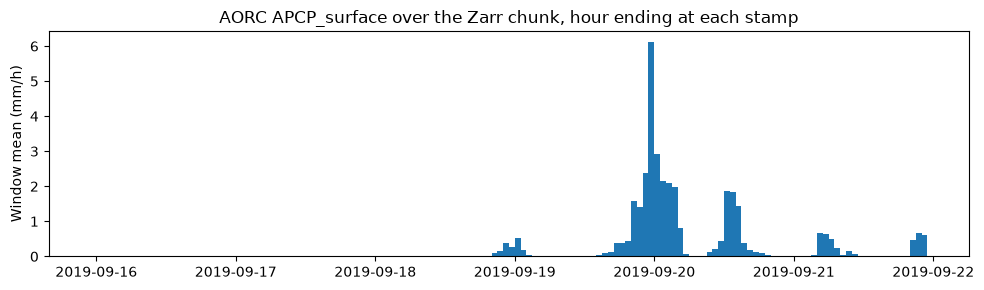

In [4]:
variables = pd.DataFrame(RasDssGrid.zarr_variables(store))
display(variables[["name", "units", "description", "steps", "ny", "nx", "accumulation_seconds"]])

# One AORC chunk (144 hours from 16 Sep 2019, 128 x 256 cells) held by the subset.
window = RasDssGrid.read_zarr(store, "APCP_surface", steps=(6192, 6336), rows=(1792, 1920), cols=(3328, 3584))
cells = np.asarray(window.cells)
hours = pd.to_datetime(np.asarray(window.times), unit="s")
west, dx, _, south, _, dy = window.transform
print(f"window: {cells.shape[0]} hours x {cells.shape[1]} x {cells.shape[2]} cells; "
      f"lon {west:.3f} to {west + dx * cells.shape[2]:.3f}, lat {south:.3f} to {south + dy * cells.shape[1]:.3f}; "
      f"units {window.units}")
basin_mean = np.nanmean(cells, axis=(1, 2))
fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(hours, basin_mean, width=-1 / 24, align="edge")
ax.set_ylabel("Window mean (mm/h)")
ax.set_title("AORC APCP_surface over the Zarr chunk, hour ending at each stamp")
plt.tight_layout()

### Import the same three hours from Zarr and from NetCDF

The envelope is stated in SHG metres on whole 2,000 m cells; the importer refuses
an extent that is not on whole cells instead of moving it. Each source is imported
with each resampling method.

In [5]:
times = (dt.datetime(2019, 9, 19, 23), dt.datetime(2019, 9, 20, 1))
lonlat_box = (-102.2, 35.0, -100.2, 35.9)
x0, y0, x1, y1 = gpd.GeoSeries([box(*lonlat_box)], crs="EPSG:4326").to_crs("EPSG:5070").total_bounds
envelope = (math.ceil(x0 / 2000) * 2000, math.ceil(y0 / 2000) * 2000,
            math.floor(x1 / 2000) * 2000, math.floor(y1 / 2000) * 2000)
print("SHG envelope (m):", envelope)

imports = {}
for method in ("near", "bilinear", "average"):
    for source in ("zarr", "netcdf"):
        target = out / f"aorc_{source}_{method}.dss"
        parts = {"A": "SHG", "B": "TX PANHANDLE", "F": f"AORC {source.upper()} {method.upper()}"}
        common = dict(envelope=envelope, target_crs="SHG", cell_size=2000, method=method, parts=parts)
        if source == "zarr":
            result = RasDssGrid.import_zarr(store, target, variable="APCP_surface", times=times, **common)
        else:
            result = RasDssGrid.import_gridded(netcdf_files, target, variable="APCP_surface", **common)
        imports[(source, method)] = (target, sorted(result.pathnames))

first = imports[("zarr", "near")][1]
print("records:", len(first))
for pathname in first:
    print(" ", pathname)

SHG envelope (m): (-560000, 1336000, -376000, 1444000)


records: 3
  /SHG/TX PANHANDLE/PRECIPITATION/19SEP2019:2200/19SEP2019:2300/AORC ZARR NEAR/
  /SHG/TX PANHANDLE/PRECIPITATION/19SEP2019:2300/19SEP2019:2400/AORC ZARR NEAR/
  /SHG/TX PANHANDLE/PRECIPITATION/20SEP2019:0000/20SEP2019:0100/AORC ZARR NEAR/


In [6]:
chunk_edges = (west, west + dx * cells.shape[2], south, south + dy * cells.shape[1])  # the NetCDF's extent


def edge_distance_km(record, mask):
    """Largest distance of the masked cells' centres from the AORC chunk's edge."""
    if not mask.any():
        return np.nan
    rows_, cols_ = np.nonzero(mask)
    x0_, y0_ = record["metadata"]["origin"]
    size = record["cell_size"]
    centres = gpd.GeoSeries.from_xy(x0_ + (cols_ + 0.5) * size, y0_ + (rows_ + 0.5) * size, crs="EPSG:5070").to_crs("EPSG:4326")
    lon, lat = centres.x.to_numpy(), centres.y.to_numpy()
    w_, e_, s_, n_ = chunk_edges
    km = np.minimum.reduce([(lon - w_) * 111.32 * np.cos(np.radians(lat)), (e_ - lon) * 111.32 * np.cos(np.radians(lat)),
                            (lat - s_) * 110.57, (n_ - lat) * 110.57])
    return float(np.max(np.abs(km)))


rows = []
for method in ("near", "bilinear", "average"):
    (zarr_file, zarr_paths), (nc_file, nc_paths) = imports[("zarr", method)], imports[("netcdf", method)]
    for zp, npth in zip(zarr_paths, nc_paths):
        a, record = grid(zarr_file, zp)
        b, _ = grid(nc_file, npth)
        both = np.isfinite(a) & np.isfinite(b)
        differ = (both & (a != b)) | (np.isfinite(a) != np.isfinite(b))
        rows.append({
            "method": method, "hour ending": record["end_time"],
            "valid cells zarr": int(np.isfinite(a).sum()), "valid cells netcdf": int(np.isfinite(b).sum()),
            "cells that differ": int(differ.sum()),
            "max |difference| (mm)": float(np.max(np.abs(a - b)[both])),
            "farthest from chunk edge (km)": edge_distance_km(record, differ),
        })
comparison = pd.DataFrame(rows)
comparison

,method,hour ending,valid cells zarr,valid cells netcdf,cells that differ,max |difference| (mm),farthest from chunk edge (km)
0,near,2019-09-19 23:00:00,4968,4968,0,0.000000,NaN
1,near,2019-09-20 00:00:00,4968,4968,0,0.000000,NaN
2,near,2019-09-20 01:00:00,4968,4968,0,0.000000,NaN
3,bilinear,2019-09-19 23:00:00,4962,4968,20,0.278108,2.539642
4,bilinear,2019-09-20 00:00:00,4962,4968,19,0.089978,2.539642
5,bilinear,2019-09-20 01:00:00,4962,4968,14,0.005917,2.539642
6,average,2019-09-19 23:00:00,4968,4968,8,0.049486,0.912413
7,average,2019-09-20 00:00:00,4968,4968,5,0.025982,0.912413
8,average,2019-09-20 01:00:00,4968,4968,0,0.000000,NaN


With `near` the two routes store the same cells: the NetCDF holds the same AORC
values as the Zarr chunk. With `bilinear` and `average`, the cells that differ (in
value or in being missing) all lie within a few kilometres of the chunk's edge,
which is also the edge of the NetCDF file (last column). There, each route
resamples from what lies beyond its own extent: the Zarr store continues into
neighbouring chunks, held or absent, and the NetCDF file ends.

Rain volume over the envelope, million cubic metres (mm x 4 km2 per cell / 1000):

,near,bilinear,average
hour ending,,,
19SEP2019:2300,52.122,52.091,52.138
19SEP2019:2400,125.676,125.585,125.642
20SEP2019:0100,60.702,60.621,60.633


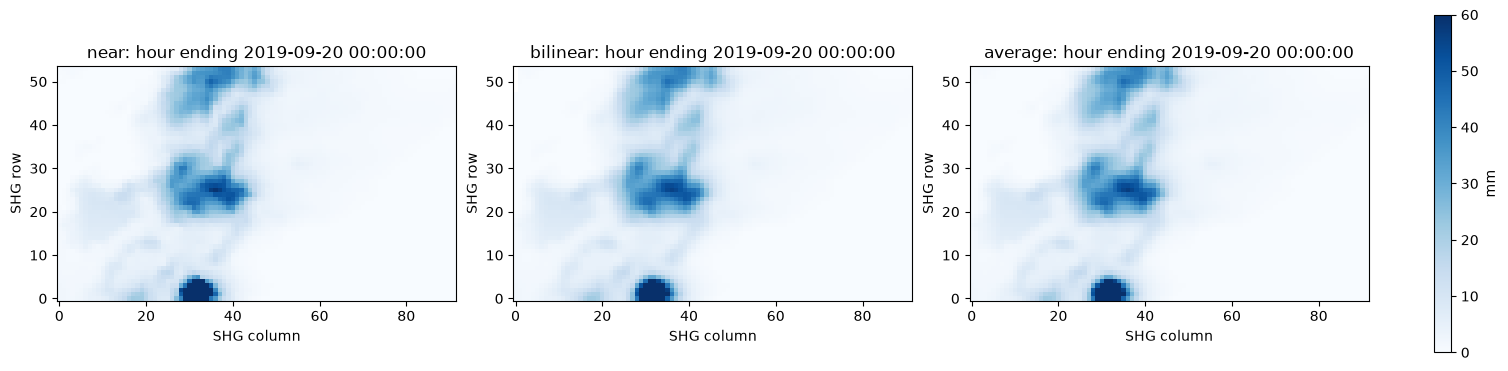

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), constrained_layout=True)
storm_hour = imports[("zarr", "near")][1][1]
for ax, method in zip(axes, ("near", "bilinear", "average")):
    target, paths = imports[("zarr", method)]
    values, record = grid(target, paths[1])
    image = ax.imshow(values, origin="lower", cmap="Blues", vmin=0, vmax=60)
    ax.set_title(f"{method}: hour ending {record['end_time']}")
    ax.set_xlabel("SHG column"); ax.set_ylabel("SHG row")
fig.colorbar(image, ax=axes, label="mm")
totals = pd.DataFrame({m: [np.nansum(grid(imports[("zarr", m)][0], p)[0]) * 4.0 / 1000.0
                           for p in imports[("zarr", m)][1]] for m in ("near", "bilinear", "average")},
                      index=[p.split("/")[5] for p in imports[("zarr", "near")][1]])
totals.index.name = "hour ending"
print("Rain volume over the envelope, million cubic metres (mm x 4 km2 per cell / 1000):")
totals.round(3)

### A projected US-survey-foot target

User models often use a State Plane CRS in US survey feet. The importer's
`cell_size` is always in **metres**, also for a foot target: 609.6 m is 2,000 US
survey feet within the stored precision. Each record reports the requested and
stored cell size and their difference in metres. A foot target must be Transverse
Mercator: the Texas North Central zone (EPSG:2276, Lambert conformal conic) is
refused while the run is planned, so this example targets NAD83 New Mexico East
(ftUS), EPSG:2257, a Transverse Mercator zone adjoining the Panhandle. Many
State Plane zones, Louisiana South among them, are Lambert zones: for those, import
to SHG.

In [8]:
for epsg in (2276, 2257):
    target_wkt = gpd.GeoSeries([], crs=f"EPSG:{epsg}").crs.to_wkt(version="WKT1_GDAL")
    ft_box = gpd.GeoSeries([box(*lonlat_box)], crs="EPSG:4326").to_crs(f"EPSG:{epsg}").total_bounds
    cell_ft = 2000.0
    ft_envelope = (math.ceil(ft_box[0] / cell_ft) * cell_ft, math.ceil(ft_box[1] / cell_ft) * cell_ft,
                   math.floor(ft_box[2] / cell_ft) * cell_ft, math.floor(ft_box[3] / cell_ft) * cell_ft)
    ft_file = out / f"aorc_epsg{epsg}_ft.dss"
    try:
        ft = RasDssGrid.import_gridded(store, ft_file, variable="APCP_surface", times=times,
                                    envelope=ft_envelope, envelope_crs=target_wkt, target_crs=target_wkt,
                                    cell_size=cell_ft * 1200 / 3937, method="bilinear",
                                    parts={"A": f"EPSG{epsg}-FT", "B": "TX PANHANDLE", "F": "AORC ZARR"})
    except Exception as exc:
        print(f"EPSG:{epsg} refused: {type(exc).__name__}: {str(exc).split('unsupported:')[-1].strip()}")
        print("file left behind:", ft_file.exists())
        continue
    print(f"EPSG:{epsg} imported: {len(ft.pathnames)} records")
record = ft.records[0]
keys = ["pathname", "nx", "ny", "cell_size", "cell_size_requested_metres",
        "cell_size_stored_metres", "cell_size_difference_metres", "units", "data_type"]
display(pd.Series({k: record[k] for k in keys}))
stored = RasDss.read_grid(ft_file, ft.pathnames[0])
print("read back: cell size", stored["cell_size"], "| CRS:", gpd.GeoSeries([], crs=stored["crs"]).crs.name)

EPSG:2276 refused: DssUnsupportedRecordError: linear unit other than the metre (0 record(s) already written remain)
file left behind: False


EPSG:2257 imported: 3 records


pathname                       /EPSG2257-FT/TX PANHANDLE/PRECIPITATION/19SEP2...
nx                                                                           302
ny                                                                           172
cell_size                                                                 2000.0
cell_size_requested_metres                                            609.601219
cell_size_stored_metres                                               609.601219
cell_size_difference_metres                                                  0.0
units                                                                         MM
data_type                                                                PER-CUM
dtype: object

read back: cell size 2000.0 | CRS: NAD83 / New Mexico East (ftUS)


### HDF5 (IMERG) and reproducible threading

The importer reads HDF5 directly. This IMERG file states an instant (11:00 UTC);
its half-hour period appears only in the file name, which the importer does not
take as a statement of the period by default. `window_rule="vortex"` applies
HEC-Vortex's file-name rule for GPM products and stamps 11:00 to 11:30, and
`align="vortex"` accepts Vortex's whole-cell rounding of the extent. Both are
explicit choices here.

From ras-commander-fast-dss 0.1.2 an import uses every core by default; `threads=1`
gives the same records. Both runs are compared record by record.

In [9]:
print("IMERG variables:", RasDssGrid.list_variables(imerg))
progress_calls = []
runs = {}
for label, threads in (("threads=1", 1), ("default (all cores)", None)):
    target = out / f"imerg_{'one' if threads == 1 else 'all'}.dss"
    result = RasDssGrid.import_gridded(imerg, target, variable="precipitationCal", target_crs="SHG",
                                       cell_size=10000, method="bilinear", align="vortex", window_rule="vortex", threads=threads,
                                       parts={"A": "SHG", "B": "IMERG", "F": "HDF5"},
                                       progress=lambda state: progress_calls.append(state))
    runs[label] = (target, result)
    r = result.records[0]
    print(f"{label}: {r['pathname']} {r['nx']} x {r['ny']} cells, {r['units']}, {r['data_type']}")
(a_file, a), (b_file, b) = runs.values()
same = all(np.array_equal(grid(a_file, p)[0], grid(b_file, p)[0], equal_nan=True) for p in a.pathnames)
print("same pathnames:", sorted(a.pathnames) == sorted(b.pathnames), "| same cells:", same,
      "| progress callbacks:", len(progress_calls))

IMERG variables: ['precipitationCal']
threads=1: /SHG/IMERG/PRECIPITATION/03JAN2017:1100/03JAN2017:1130/HDF5/ 580 x 310 cells, MM, PER-CUM


default (all cores): /SHG/IMERG/PRECIPITATION/03JAN2017:1100/03JAN2017:1130/HDF5/ 580 x 310 cells, MM, PER-CUM
same pathnames: True | same cells: True | progress callbacks: 2


### Stage IV GRIB1 beside AORC for the same day

NCEP Stage IV analyses before 20 July 2020 are GRIB1; ras-commander-fast-dss 0.1.2
reads them (`gridded_grib1_stage4`). The 24-hour analysis ending 12:00 UTC on
20 September 2019 is imported to the same SHG envelope and set beside the sum of
the 24 AORC hours over the same period. They are different products, so their
totals are compared, not expected to be equal.

Stage IV 20190920: conus_20190920_24h.grb (archive SHA-256 f47187cf1c4aa2ad...)
variables: ['Total_precipitation_surface_24_Hour_Accumulation']


Stage IV record /SHG/TX PANHANDLE/PRECIPITATION/19SEP2019:1200/20SEP2019:1200/STAGE IV 24H/ (MM, PER-CUM)
AORC hours summed: 24
envelope mean: Stage IV 24.7 mm, AORC 24.8 mm


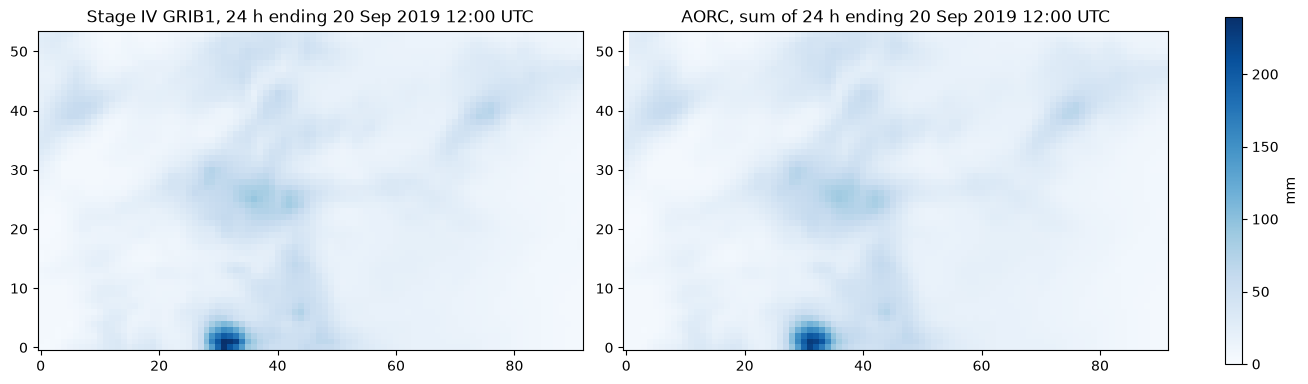

In [10]:
stage4_2019 = fetch_stage4("20190920")
print("variables:", RasDssGrid.list_variables(stage4_2019))
grib1_dss = out / "stage4_grib1_2019.dss"
grib1 = RasDssGrid.import_gridded(stage4_2019, grib1_dss, product="total_precipitation", envelope=envelope,
                                  cell_size=2000, method="bilinear",
                                  parts={"A": "SHG", "B": "TX PANHANDLE", "F": "STAGE IV 24H"})
stage4_day, stage4_rec = grid(grib1_dss, grib1.pathnames[0])
aorc_day_dss = out / "aorc_day.dss"
aorc_day = RasDssGrid.import_zarr(store, aorc_day_dss, variable="APCP_surface",
                                  times=(dt.datetime(2019, 9, 19, 13), dt.datetime(2019, 9, 20, 12)),
                                  envelope=envelope, target_crs="SHG", cell_size=2000, method="bilinear",
                                  parts={"A": "SHG", "B": "TX PANHANDLE", "F": "AORC DAY"})
aorc_total = np.sum([grid(aorc_day_dss, p)[0] for p in aorc_day.pathnames], axis=0)
print(f"Stage IV record {grib1.pathnames[0]} ({stage4_rec['units']}, {stage4_rec['data_type']})")
print(f"AORC hours summed: {len(aorc_day.pathnames)}")
print(f"envelope mean: Stage IV {np.nanmean(stage4_day):.1f} mm, AORC {np.nanmean(aorc_total):.1f} mm")
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), constrained_layout=True)
top = np.nanmax([stage4_day, aorc_total])
for ax, values, title in ((axes[0], stage4_day, "Stage IV GRIB1, 24 h"), (axes[1], aorc_total, "AORC, sum of 24 h")):
    image = ax.imshow(values, origin="lower", cmap="Blues", vmin=0, vmax=top)
    ax.set_title(title + " ending 20 Sep 2019 12:00 UTC")
fig.colorbar(image, ax=axes, label="mm")

# Example 2: An MRMS storm over NewOrleansMetro, through every grid tool

MRMS MultiSensor QPE Pass 2 for the 24 hours ending 12:00 UTC on 11 April 2024, the
New Orleans event used by notebook 917, over the NewOrleansMetro 2D area. The
model geometry comes through RAS Commander; the 2D area perimeter, in the model's
Louisiana South (ftUS) CRS, is written as a shapefile with its `.prj` for the zonal
tools.

In [11]:
project = RasExamples.extract_project("NewOrleansMetro", output_path=run_root / "projects")
ras = init_ras_project(project, ras_version="7.0", load_results_summary=False, hide_intro=True)
geom_hdf = next(Path(p) for p in ras.geom_df["hdf_path"] if Path(p).is_file())
areas = HdfMesh.get_mesh_areas(geom_hdf)
print("model CRS:", areas.crs.name, "| 2D areas:", ", ".join(areas["mesh_name"]))
zones = out / "mesh_areas.shp"
areas[["mesh_name", "geometry"]].to_file(zones)

sx0, sy0, sx1, sy1 = areas.to_crs("EPSG:5070").total_bounds
mrms_envelope = (math.floor(sx0 / 2000) * 2000 - 4000, math.floor(sy0 / 2000) * 2000 - 4000,
                 math.ceil(sx1 / 2000) * 2000 + 4000, math.ceil(sy1 / 2000) * 2000 + 4000)
lonlat = tuple(areas.to_crs("EPSG:4326").total_bounds)
mrms_dir = run_root / "mrms"
hourly_files = PrecipMrms.download(lonlat, "2024-04-10 13:00", "2024-04-11 12:00",
                                   mrms_dir / "01H", product="GaugeCorr_QPE_01H")
daily_files = PrecipMrms.download(lonlat, "2024-04-11 12:00", "2024-04-11 12:00",
                                  mrms_dir / "24H", product="GaugeCorr_QPE_24H")
print(f"{len(hourly_files)} hourly files ({hourly_files[0].name} ... {hourly_files[-1].name}); "
      f"{len(daily_files)} daily file ({daily_files[0].name})")
print("SHG envelope (m):", mrms_envelope)

2026-11-12 11:05:32 - ras_commander.fast_hdf - WARNING - Ignoring incompatible ras-commander-fast-hdf extension


model CRS: NAD83(HARN) / Louisiana South (ftUS) | 2D areas: NewOrleans Metro


24 hourly files (MRMS_MultiSensor_QPE_01H_Pass2_00.00_20240410-130000.grib2 ... MRMS_MultiSensor_QPE_01H_Pass2_00.00_20240411-120000.grib2); 1 daily file (MRMS_MultiSensor_QPE_24H_Pass2_00.00_20240411-120000.grib2)
SHG envelope (m): (556000, 772000, 578000, 796000)


In [12]:
print("hourly variable:", RasDssGrid.list_variables(hourly_files[0]))
hourly = out / "mrms_01h.dss"
hourly_import = RasDssGrid.import_gridded(hourly_files, hourly, product="mrms_qpe", envelope=mrms_envelope,
                                          cell_size=2000, parts={"A": "SHG", "B": "NEW ORLEANS", "F": "MRMS 01H"})
paths = sorted(hourly_import.pathnames, key=lambda p: grid(hourly, p)[1]["start_time"])

daily = out / "mrms_24h.dss"
try:
    RasDssGrid.import_gridded(daily_files, daily, product="mrms_qpe", envelope=mrms_envelope, cell_size=2000,
                              parts={"A": "SHG", "B": "NEW ORLEANS", "F": "MRMS 24H"})
except Exception as exc:
    reason = str(exc).split("refused time of ")[-1].split(". Give")[0]
    print("without a window:", type(exc).__name__, "-", reason)
daily_import = RasDssGrid.import_gridded(daily_files, daily, product="mrms_qpe", window_rule="accumulation:24H",
                                         envelope=mrms_envelope, cell_size=2000,
                                         parts={"A": "SHG", "B": "NEW ORLEANS", "F": "MRMS 24H"})
print("24H record:", daily_import.pathnames[0])
stage4_source = fetch_stage4("20240411")
print("Stage IV variable:", RasDssGrid.list_variables(stage4_source))
stage4 = out / "stage4_24h.dss"
stage4_import = RasDssGrid.import_gridded(stage4_source, stage4, product="total_precipitation", envelope=mrms_envelope,
                                          cell_size=2000, method="bilinear",
                                          parts={"A": "SHG", "B": "NEW ORLEANS", "F": "STAGE IV 24H"})
stage4_total, stage4_record = grid(stage4, stage4_import.pathnames[0])
print("Stage IV record:", stage4_import.pathnames[0], stage4_record["units"], stage4_record["data_type"])
info = RasDssGrid.series_info(hourly, paths[0])
pd.Series({k: info[k] for k in ("records", "start", "end", "data_type", "units", "nx", "ny") if k in info})

hourly variable: ['MultiSensor_QPE_01H_Pass2_altitude_above_msl']


without a window: DssUnsupportedRecordError - MultiSensor_QPE_24H_Pass2_altitude_above_msl: precipitation at an instant states no period, so its D and E parts cannot say when the depth fell


24H record: /SHG/NEW ORLEANS/PRECIPITATION/10APR2024:1200/11APR2024:1200/MRMS 24H/
Stage IV 20240411: conus_20240411_24h.grb2 (archive SHA-256 ecbcda69dd5f5501...)
Stage IV variable: ['Total_precipitation_surface_24_Hour_Accumulation']
Stage IV record: /SHG/NEW ORLEANS/PRECIPITATION/10APR2024:1200/11APR2024:1200/STAGE IV 24H/ MM PER-CUM


records                  24
start        10APR2024:1200
end          11APR2024:1200
data_type           PER-CUM
units                    MM
nx                       11
ny                       12
dtype: object

The 24-hour product states an instant in its GRIB2 header, so the importer refuses
it until the period is stated with `window_rule="accumulation:24H"`.

### Hourly grids against the 24-hour product

envelope mean: hourly sum 98.9 mm, 24H product 98.9 mm; max |difference| 0.0000 mm


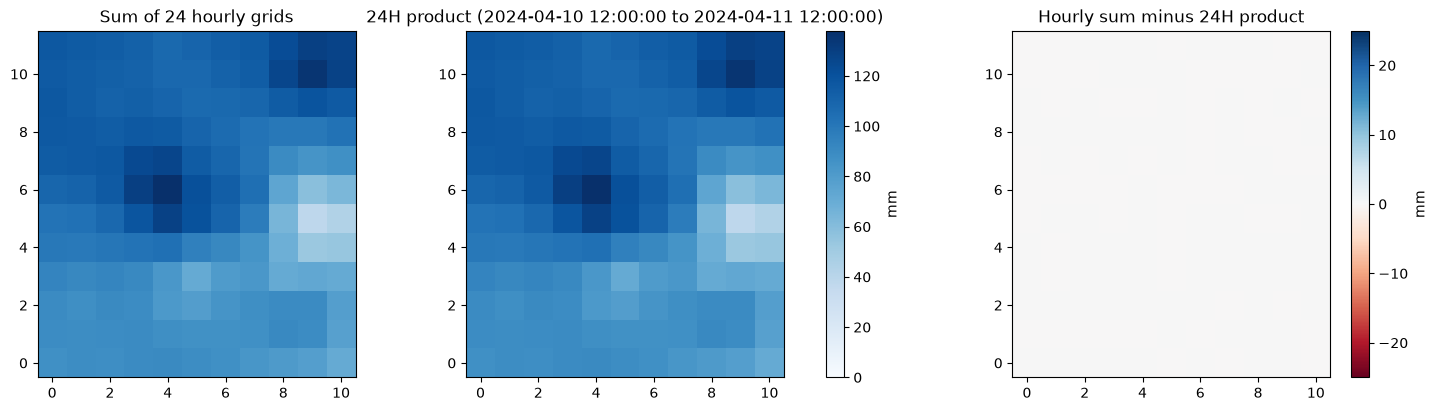

In [13]:
stack = np.stack([grid(hourly, p)[0] for p in paths])
hourly_total = stack.sum(axis=0)
daily_total, daily_record = grid(daily, daily_import.pathnames[0])
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, values, title in ((axes[0], hourly_total, "Sum of 24 hourly grids"),
                          (axes[1], daily_total, f"24H product ({daily_record['start_time']} to {daily_record['end_time']})")):
    image = ax.imshow(values, origin="lower", cmap="Blues", vmin=0, vmax=np.nanmax([hourly_total, daily_total]))
    ax.set_title(title)
fig.colorbar(image, ax=axes[:2], label="mm")
diff = axes[2].imshow(hourly_total - daily_total, origin="lower", cmap="RdBu", vmin=-25, vmax=25)
axes[2].set_title("Hourly sum minus 24H product")
fig.colorbar(diff, ax=axes[2], label="mm")
print(f"envelope mean: hourly sum {np.nanmean(hourly_total):.1f} mm, 24H product {np.nanmean(daily_total):.1f} mm; "
      f"max |difference| {np.nanmax(np.abs(hourly_total - daily_total)):.4f} mm")

### Calculator, sanitizer, clipper and raster calculator

- `calculate` divides every valid cell by 25.4 and relabels the units, giving inches.
- `sanitize` replaces cells at or below 0 mm and at or above 200 mm. It reports
  the effect even when no cell changes; no bad cell is invented to show one.
- `clip` subsets to the model's own extent plus one cell, by nearest neighbour.
- `calculate_raster` divides each hourly grid by the 24H product (a timed DSS grid
  used as a static factor), giving each hour's share of the daily total.

In [14]:
inches = out / "mrms_01h_in.dss"
RasDssGrid.calculate(hourly, inches, divide=25.4, units="IN",
                     parts={"A": "SHG", "B": "NEW ORLEANS", "F": "MRMS 01H IN"})
inches_stack = np.stack([grid(inches, p.replace("/MRMS 01H/", "/MRMS 01H IN/"))[0] for p in paths])

sanitized = out / "mrms_01h_sanitized.dss"
RasDssGrid.sanitize(hourly, sanitized, minimum=-0.001, maximum=200.0, minimum_replacement=0.0,
                    parts={"A": "SHG", "B": "NEW ORLEANS", "F": "MRMS 01H SAN"})
sanitized_stack = np.stack([grid(sanitized, p.replace("/MRMS 01H/", "/MRMS 01H SAN/"))[0] for p in paths])
changed = int((~np.isclose(sanitized_stack, stack, equal_nan=True)).sum())

clipped = out / "mrms_01h_clip.dss"
cx0, cy0, cx1, cy1 = mrms_envelope
clip_result = RasDssGrid.clip(hourly, clipped, envelope=(cx0 + 2000, cy0 + 2000, cx1 - 2000, cy1 - 2000),
                              envelope_crs="SHG", parts={"A": "SHG", "B": "NEW ORLEANS", "F": "MRMS 01H CLIP"})

share = out / "mrms_01h_share.dss"
share_result = RasDssGrid.calculate_raster(hourly, daily, share, operation="divide", static_raster=True,
                                           units="FRACTION", parts={"A": "SHG", "B": "NEW ORLEANS", "F": "SHARE OF 24H"})
share_stack = np.stack([grid(share, p.replace("/MRMS 01H/", "/SHARE OF 24H/"))[0] for p in paths])
pd.DataFrame([
    {"tool": "calculate (/25.4)", "check": "max |mm/25.4 - in|",
     "value": float(np.nanmax(np.abs(stack / 25.4 - inches_stack)))},
    {"tool": "sanitize", "check": "cells changed", "value": changed},
    {"tool": "clip", "check": "grid before -> after",
     "value": f"{hourly_import.records[0]['nx']}x{hourly_import.records[0]['ny']} -> "
              f"{clip_result.records[0]['nx']}x{clip_result.records[0]['ny']}"},
    {"tool": "calculate_raster (/24H)", "check": "envelope-mean sum of hourly shares",
     "value": float(np.nanmean(np.nansum(share_stack, axis=0)))},
])

,tool,check,value
0,calculate (/25.4),max |mm/25.4 - in|,0.0
1,sanitize,cells changed,0
2,clip,grid before -> after,11x12 -> 9x10
3,calculate_raster (/24H),envelope-mean sum of hourly shares,1.0


### Normalizer

`normalize` scales the source grids in each interval so their total matches the
normals cell by cell. A cell whose normal is missing is written as missing; a cell
with no source rain stays 0. The MRMS 24H Pass 2 product equals the sum of the
hourly grids (above), so it would be no independent total. The normal here is NCEP's
Stage IV analysis for the same 24 hours (12 UTC to 12 UTC), a separate
multi-sensor product, imported natively from its GRIB2 file. The result keeps the
MRMS hourly pattern and takes the Stage IV daily total in each cell. Which product
is closer to the true rainfall is not assessed here.

records: 24 | intervals: 1 | cells made missing by a missing normal: 0
max |normalized total - Stage IV| where MRMS had rain: 0.0000 mm
envelope mean over 24 h: MRMS 98.9 mm, Stage IV 161.9 mm, normalized MRMS 161.9 mm


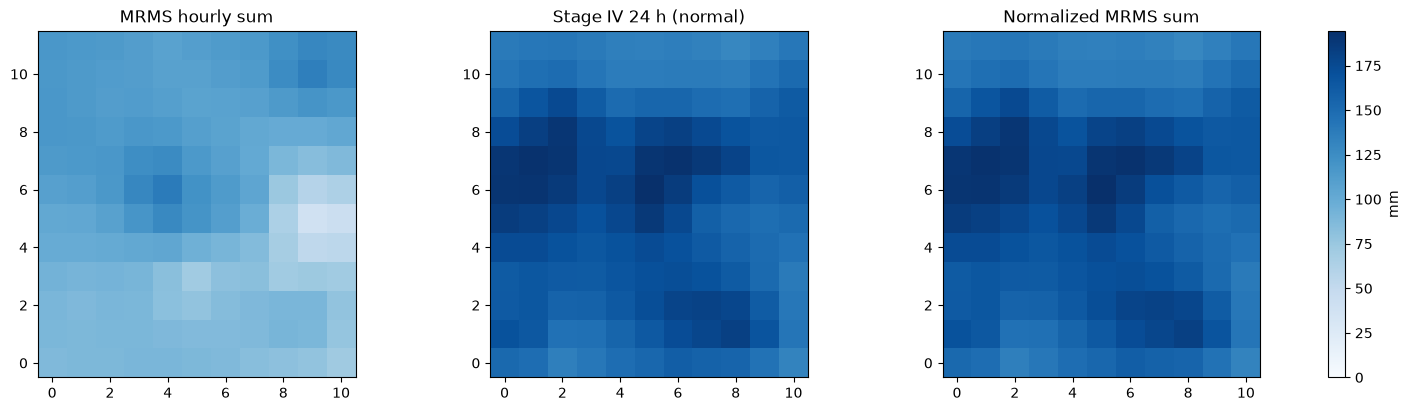

In [15]:
normalized = out / "mrms_01h_normalized.dss"
norm = RasDssGrid.normalize(hourly, stage4, normalized, start=dt.datetime(2024, 4, 10, 12),
                            end=dt.datetime(2024, 4, 11, 12), interval=dt.timedelta(hours=24),
                            parts={"A": "SHG", "B": "NEW ORLEANS", "F": "MRMS 01H NORM24"})
norm_stack = np.stack([grid(normalized, p.replace("/MRMS 01H/", "/MRMS 01H NORM24/"))[0] for p in paths])
norm_total = norm_stack.sum(axis=0)
rain = np.isfinite(stage4_total) & (hourly_total > 0)
print("records:", len(norm.pathnames), "| intervals:", len(norm.intervals),
      "| cells made missing by a missing normal:", norm.cells_made_missing_by_normal)
print(f"max |normalized total - Stage IV| where MRMS had rain: {np.nanmax(np.abs(norm_total - stage4_total)[rain]):.4f} mm")
print(f"envelope mean over 24 h: MRMS {np.nanmean(hourly_total):.1f} mm, Stage IV {np.nanmean(stage4_total):.1f} mm, "
      f"normalized MRMS {np.nanmean(norm_total):.1f} mm")
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
top = np.nanmax([hourly_total, stage4_total, norm_total])
for ax, values, title in ((axes[0], hourly_total, "MRMS hourly sum"), (axes[1], stage4_total, "Stage IV 24 h (normal)"),
                          (axes[2], norm_total, "Normalized MRMS sum")):
    image = ax.imshow(values, origin="lower", cmap="Blues", vmin=0, vmax=top)
    ax.set_title(title)
fig.colorbar(image, ax=axes, label="mm")

For this storm, Stage IV's 24-hour total over the envelope is well above the MRMS
sum (printed above), and the normalized grids take Stage IV's totals with MRMS's
hourly timing. The notebook does not judge which product is closer to the rainfall
that fell; the normalizer imposes the normal it is given.

### Time shift, time-step resampling and window reads

`shift_times` is plain arithmetic on the stamps, not a time-zone conversion: here
it moves every record 6 hours earlier, the size of the UTC-to-CST offset, and the
output is labelled as shifted. `resample_times` aggregates the PER-CUM hourly grids
to 3-hour windows that start at midnight of the first day, so complete windows keep
the volume and windows before the series are written missing.

In [16]:
shifted = out / "mrms_01h_shift.dss"
shift = RasDssGrid.shift_times(hourly, shifted, shift=dt.timedelta(hours=-6),
                               parts={"A": "SHG", "B": "NEW ORLEANS", "C": "PRECIPITATION", "F": "MRMS 01H SHIFTED -6H"})
print("first record before:", paths[0].split("/")[4:6], "after:", sorted(shift.pathnames)[0].split("/")[4:6])

print("time steps resample_times takes (minutes):", RasDssGrid.time_steps())
three_hour = out / "mrms_03h.dss"
resampled = RasDssGrid.resample_times(hourly, three_hour, 180,
                                      parts={"A": "SHG", "B": "NEW ORLEANS", "C": "PRECIPITATION", "F": "MRMS 03H"})
rows = []
for pathname in sorted(resampled.pathnames, key=lambda p: grid(three_hour, p)[1]["start_time"]):
    values, record = grid(three_hour, pathname)
    rows.append({"start": record["start_time"], "end": record["end_time"],
                 "valid cells": int(np.isfinite(values).sum()), "envelope mean (mm)": float(np.nanmean(values)) if np.isfinite(values).any() else np.nan})
display(pd.DataFrame(rows))
complete = [r for r in rows if r["valid cells"]]
print(f"3-hour total of complete windows {sum(r['envelope mean (mm)'] for r in complete):.2f} mm; "
      f"hourly total over the same hours "
      f"{np.nanmean(stack[[i for i, p in enumerate(paths) if pd.Timestamp(grid(hourly, p)[1]['start_time']) >= pd.Timestamp(complete[0]['start'])]].sum(axis=0)):.2f} mm; "
      f"dropped tail: {resampled.dropped_tail_seconds} s")

first record before: ['10APR2024:1200', '10APR2024:1300'] after: ['10APR2024:0600', '10APR2024:0700']
time steps resample_times takes (minutes): [1, 2, 3, 4, 5, 6, 10, 15, 20, 30, 60, 120, 180, 240, 360, 480, 720, 1440, 10080, 43200, 525600]


,start,end,valid cells,envelope mean (mm)
0,2024-04-10 00:00:00,2024-04-10 03:00:00,0,NaN
1,2024-04-10 03:00:00,2024-04-10 06:00:00,0,NaN
2,2024-04-10 06:00:00,2024-04-10 09:00:00,0,NaN
3,2024-04-10 09:00:00,2024-04-10 12:00:00,0,NaN
4,2024-04-10 12:00:00,2024-04-10 15:00:00,132,42.127436
5,2024-04-10 15:00:00,2024-04-10 18:00:00,132,49.091504
6,2024-04-10 18:00:00,2024-04-10 21:00:00,132,7.712045
7,2024-04-10 21:00:00,2024-04-11 00:00:00,132,0.000000
8,2024-04-11 00:00:00,2024-04-11 03:00:00,132,0.000000
9,2024-04-11 03:00:00,2024-04-11 06:00:00,132,0.000000


3-hour total of complete windows 98.93 mm; hourly total over the same hours 98.93 mm; dropped tail: 0 s


In [17]:
window6 = RasDssGrid.read_window(hourly, paths[0], "10APR2024:1200", "10APR2024:1800")
nearest = RasDssGrid.read_nearest(hourly, paths[0], "10APR2024:1430")
lowest, highest = RasDssGrid.read_min_max(hourly, paths[0], "10APR2024:1200", "11APR2024:1200")
pd.DataFrame([
    {"read": "read_window 12:00-18:00", "start": window6.start, "end": window6.end,
     "envelope mean (mm)": float(np.nanmean(window6.data))},
    {"read": "read_nearest 14:30", "start": nearest.start, "end": nearest.end,
     "envelope mean (mm)": float(np.nanmean(nearest.data))},
    {"read": "read_min_max: maximum", "start": highest.start, "end": highest.end,
     "envelope mean (mm)": float(np.nanmean(highest.data))},
    {"read": "read_min_max: minimum", "start": lowest.start, "end": lowest.end,
     "envelope mean (mm)": float(np.nanmean(lowest.data))},
])

,read,start,end,envelope mean (mm)
0,read_window 12:00-18:00,10APR2024:1200,10APR2024:1800,91.218941
1,read_nearest 14:30,10APR2024:1400,10APR2024:1500,8.249804
2,read_min_max: maximum,10APR2024:1200,11APR2024:1200,23.278128
3,read_min_max: minimum,10APR2024:1200,11APR2024:1200,0.000000


### Zonal statistics and grid-to-point

`zone_masks` lists the grid cells in each zone. `zonal_statistics` returns the
eight statistics as a table, and `grid_to_point` writes them as DSS time series,
one per zone and statistic. The zone shapefile is in NAD83(HARN) and the grid in
SHG NAD83; `assume_no_datum_shift=True` states that no datum shift is applied
between them.

{'NewOrleans Metro': 16} cells per zone
time series written: 8


grid_to_point average equals zonal_statistics average: True


,PRECIP-INC,PRECIP-INC-MIN,PRECIP-INC-MAX,PRECIP-INC-MEDIAN,PRECIP-INC-Q1,PRECIP-INC-Q3,PRECIP-INC-PCT>0,PRECIP-INC-PCT>Q1
datetime,,,,,,,,
2024-04-10 13:00:00,12.68,6.82,18.30,12.57,9.95,16.82,100.0,68.75
2024-04-10 14:00:00,26.26,19.48,36.10,24.80,22.97,29.83,100.0,68.75
2024-04-10 15:00:00,6.45,2.96,9.84,7.10,5.15,7.92,100.0,68.75
2024-04-10 16:00:00,16.65,10.03,24.19,17.33,13.42,19.06,100.0,68.75
2024-04-10 17:00:00,17.54,9.13,26.83,18.93,13.58,21.36,100.0,68.75
2024-04-10 18:00:00,17.36,14.15,19.00,17.77,17.24,18.40,100.0,68.75
2024-04-10 19:00:00,6.02,3.32,7.86,6.46,5.20,7.19,100.0,68.75
2024-04-10 20:00:00,1.51,0.48,3.15,1.30,1.14,2.29,100.0,68.75
2024-04-10 21:00:00,0.41,0.32,0.54,0.40,0.35,0.49,100.0,68.75


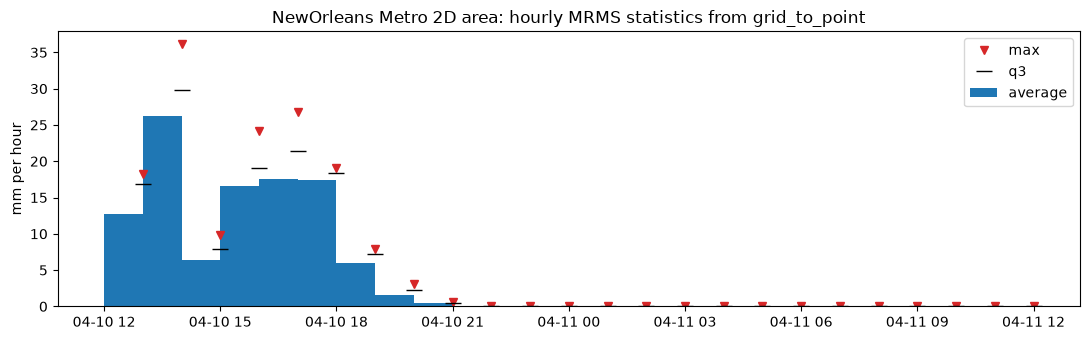

In [18]:
STATISTICS = ("average", "min", "max", "median", "q1", "q3", "pct_gt_0", "pct_gt_q1")
masks = RasDssGrid.zone_masks(hourly, zones, "mesh_name", assume_no_datum_shift=True)
print({zone: len(indices) for zone, indices in masks.items()}, "cells per zone")
table = RasDssGrid.zonal_statistics(hourly, zones, "mesh_name", assume_no_datum_shift=True)
points = out / "mrms_zones.dss"
g2p = RasDssGrid.grid_to_point(hourly, zones, "mesh_name", points, statistics=STATISTICS,
                               parts={"A": "NEW ORLEANS", "F": "MRMS 01H"}, assume_no_datum_shift=True)
print("time series written:", len(g2p.pathnames))
series = {p.split("/")[3]: RasDss.read_timeseries(points, p)["value"] for p in g2p.pathnames}
frame = pd.DataFrame(series)
print("grid_to_point average equals zonal_statistics average:",
      bool(np.allclose(frame.iloc[:, 0].to_numpy(), table["average"].to_numpy(), equal_nan=True)))
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(frame.index, frame["PRECIP-INC"], width=-1 / 24, align="edge", label="average")
ax.plot(frame.index, frame["PRECIP-INC-MAX"], "v", color="tab:red", label="max")
ax.plot(frame.index, frame["PRECIP-INC-Q3"], "_", color="black", markersize=12, label="q3")
ax.set_ylabel("mm per hour")
ax.set_title("NewOrleans Metro 2D area: hourly MRMS statistics from grid_to_point")
ax.legend()
plt.tight_layout()
frame.round(2).head(24)

## Key takeaways

- `RasDssGrid` passes every engine option through unchanged and returns the
  engine's result; `RasDss.read_grid` reads the records back on any backend.
- A run is planned before it writes: an extent off whole cells, or a period the
  source does not state, is refused rather than guessed.
- `cell_size` is metres even for a foot target; read the stored size back.
- Shift and resampling are arithmetic on stamps and periods; time zones are the
  caller's decision.
- Design or observed, these grids are model inputs. Check periods, coverage and
  totals in the receiving model before treating a run as rainfall-driven.

See [Native Rust Engines](https://rascommander.info/ras/native-engine/#gridded-import-and-tools) and
[DSS Read and Write Backends](https://rascommander.info/ras/user-guide/dss-native-backend/#engine-only-operations).